## Lab 3 - Multiclass Classification

##### Group: 26
##### Student Name: Al Amin Alif, Md Rakib Uddin


## Public version note

Prepared for publication in November 2026 from the original Group 26 coursework. Original author names and group context are retained; university email addresses are omitted. Setup and compatibility changes are listed in PUBLICATION_NOTES.md. Outputs in this version are regenerated during verification.



### Part A - Data Understanding & Exploration

In [1]:
# --- Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

Matplotlib is building the font cache; this may take a moment.


In [2]:
# --- Load Dataset ---
df = pd.read_csv('Mall_Customers.csv')

print(f'Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns')
print()
print('First 5 rows:')
df.head()

Dataset shape: 200 rows x 6 columns

First 5 rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Churn Risk
0,1,Male,19,15,39,Medium Risk
1,2,Male,21,15,81,Low Risk
2,3,Female,20,16,6,Medium Risk
3,4,Female,23,16,77,Low Risk
4,5,Female,31,17,40,Low Risk


In [3]:
# --- Data Types & Structure ---
print('Column data types:')
print(df.dtypes)
print()
print('Dataset Info:')
df.info()

Column data types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
Churn Risk                  str
dtype: object

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
 5   Churn Risk              200 non-null    str  
dtypes: int64(4), str(2)
memory usage: 9.5 KB


In [4]:
# --- Data Quality Checks ---
print('Missing values per column:')
print(df.isnull().sum())
print()
print(f'Duplicate rows: {df.duplicated().sum()}')
print()
print('Unique values in categorical columns:')
print(f"  Gender:     {df['Gender'].unique()}")
print(f"  Churn Risk: {df['Churn Risk'].unique()}")

Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
Churn Risk                0
dtype: int64

Duplicate rows: 0

Unique values in categorical columns:
  Gender:     <StringArray>
['Male', 'Female']
Length: 2, dtype: str
  Churn Risk: <StringArray>
['Medium Risk', 'Low Risk', 'High Risk']
Length: 3, dtype: str


In [5]:
# --- Descriptive Statistics ---
# Numerical features only (excluding CustomerID as it is an identifier)
df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].describe().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


Churn Risk class counts:
Churn Risk
Low Risk       140
Medium Risk     28
High Risk       32
Name: count, dtype: int64

Class proportions (%):
Churn Risk
Low Risk       70.0
Medium Risk    14.0
High Risk      16.0
Name: count, dtype: float64


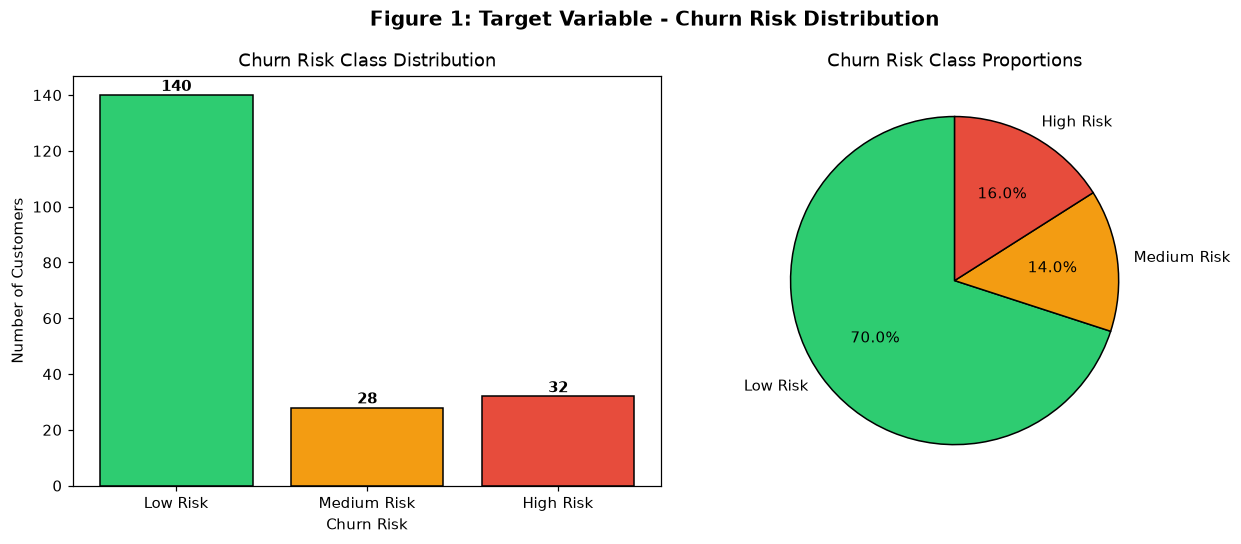

In [6]:
# --- Target Variable Distribution ---
order = ['Low Risk', 'Medium Risk', 'High Risk']
palette = {'Low Risk': '#2ecc71', 'Medium Risk': '#f39c12', 'High Risk': '#e74c3c'}

counts = df['Churn Risk'].value_counts().reindex(order)
print('Churn Risk class counts:')
print(counts)
print()
print('Class proportions (%):')
print((counts / len(df) * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
axes[0].bar(counts.index, counts.values,
            color=[palette[x] for x in counts.index], edgecolor='black')
axes[0].set_title('Churn Risk Class Distribution')
axes[0].set_xlabel('Churn Risk')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1.5, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=counts.index,
            colors=[palette[x] for x in counts.index],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'black'})
axes[1].set_title('Churn Risk Class Proportions')

plt.suptitle('Figure 1: Target Variable - Churn Risk Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

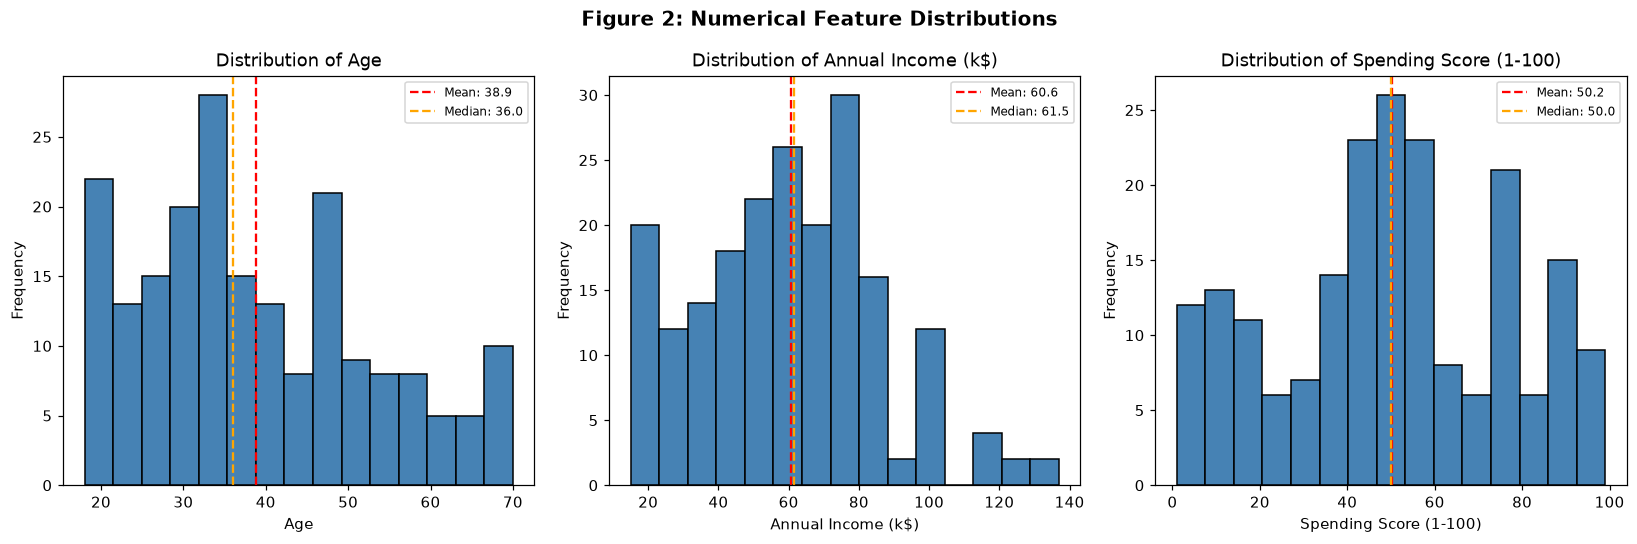

In [7]:
# --- Distributions of Numerical Features ---
num_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, num_cols):
    ax.hist(df[col], bins=15, color='steelblue', edgecolor='black')
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange', linestyle='--', label=f'Median: {df[col].median():.1f}')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)

plt.suptitle('Figure 2: Numerical Feature Distributions', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

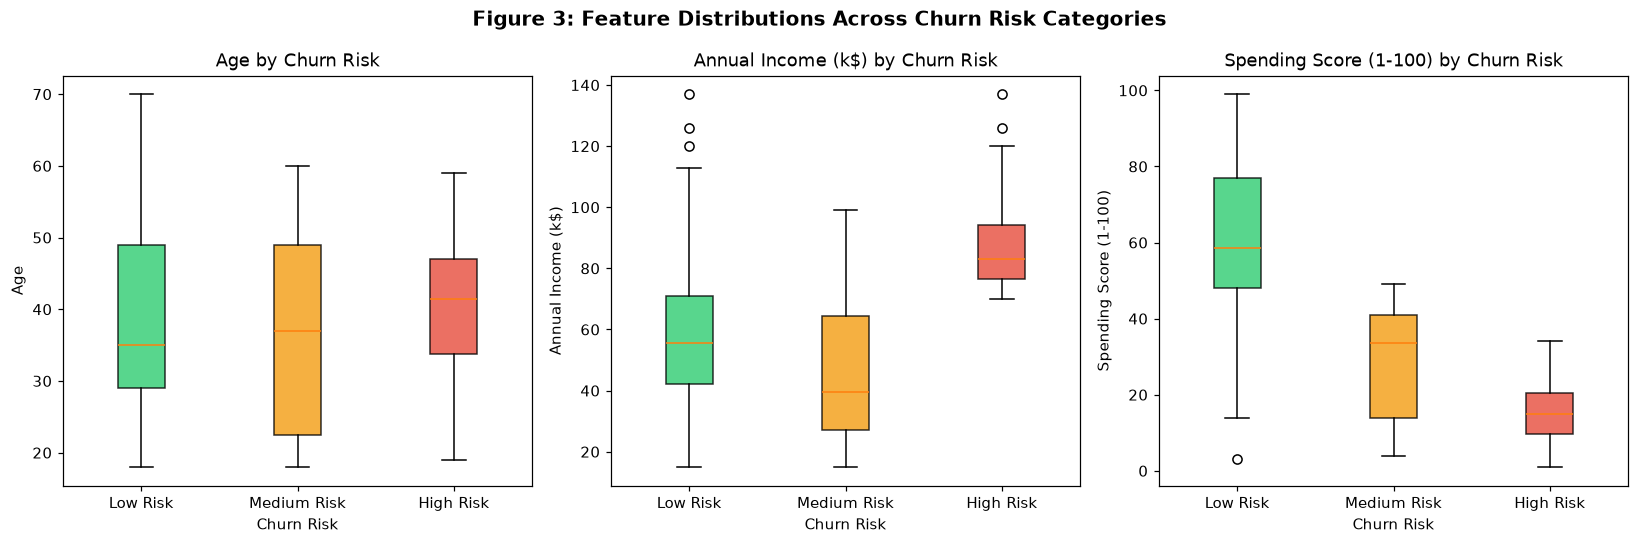

In [8]:
# --- Boxplots: Feature Distributions by Churn Risk ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, num_cols):
    data_by_class = [df[df['Churn Risk'] == c][col].values for c in order]
    bp = ax.boxplot(data_by_class, tick_labels=order, patch_artist=True, notch=False)
    for patch, cls in zip(bp['boxes'], order):
        patch.set_facecolor(palette[cls])
        patch.set_alpha(0.8)
    ax.set_title(f'{col} by Churn Risk')
    ax.set_xlabel('Churn Risk')
    ax.set_ylabel(col)

plt.suptitle('Figure 3: Feature Distributions Across Churn Risk Categories', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

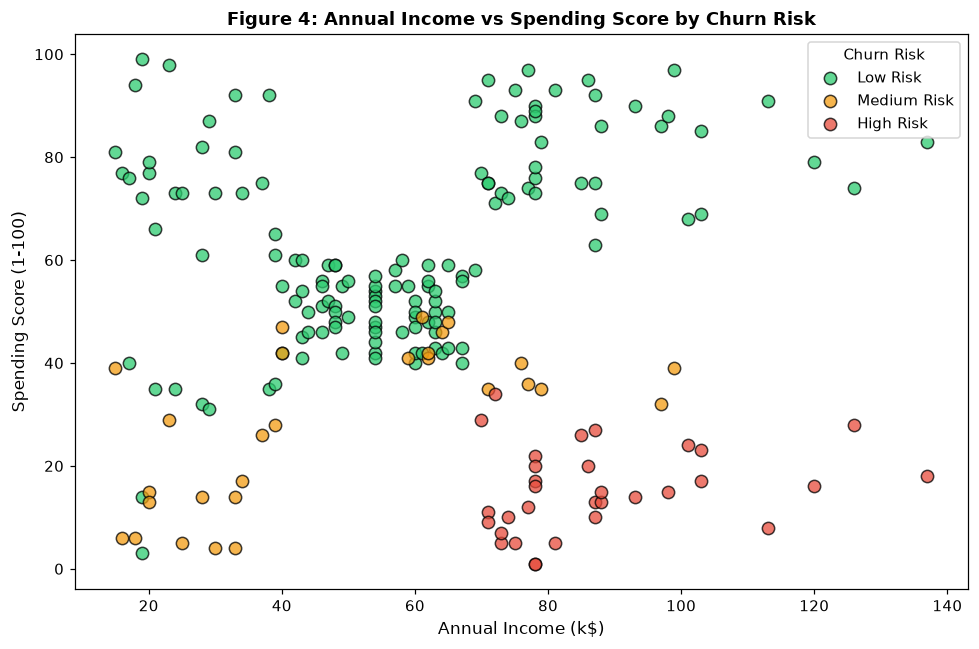

In [9]:
# --- Scatter Plot: Annual Income vs Spending Score coloured by Churn Risk ---
fig, ax = plt.subplots(figsize=(9, 6))

for cls in order:
    sub = df[df['Churn Risk'] == cls]
    ax.scatter(sub['Annual Income (k$)'], sub['Spending Score (1-100)'],
               label=cls, color=palette[cls], alpha=0.75,
               edgecolors='black', s=65)

ax.set_xlabel('Annual Income (k$)', fontsize=11)
ax.set_ylabel('Spending Score (1-100)', fontsize=11)
ax.set_title('Figure 4: Annual Income vs Spending Score by Churn Risk', fontsize=12, fontweight='bold')
ax.legend(title='Churn Risk')
plt.tight_layout()
plt.show()

Churn Risk counts by Gender:
Churn Risk  Low Risk  Medium Risk  High Risk
Gender                                      
Female            80           18         14
Male              60           10         18

Churn Risk proportions by Gender (%):
Churn Risk  Low Risk  Medium Risk  High Risk
Gender                                      
Female          71.4         16.1       12.5
Male            68.2         11.4       20.5


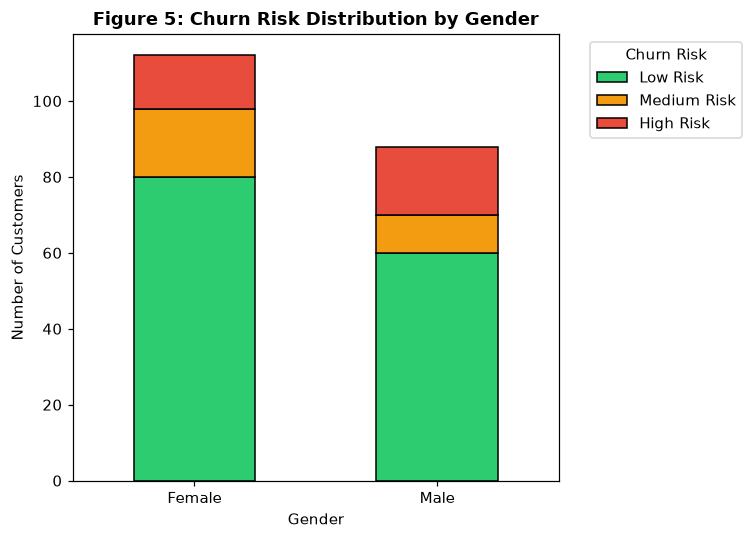

In [10]:
# --- Churn Risk by Gender ---
ct = pd.crosstab(df['Gender'], df['Churn Risk'])[order]
print('Churn Risk counts by Gender:')
print(ct)
print()
print('Churn Risk proportions by Gender (%):')
print(ct.div(ct.sum(axis=1), axis=0).mul(100).round(1))

fig, ax = plt.subplots(figsize=(7, 5))
ct.plot(kind='bar', stacked=True,
        color=[palette[c] for c in order],
        edgecolor='black', ax=ax)
ax.set_title('Figure 5: Churn Risk Distribution by Gender', fontsize=12, fontweight='bold')
ax.set_xlabel('Gender')
ax.set_ylabel('Number of Customers')
ax.legend(title='Churn Risk', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Part A - Summary of Findings

**Dataset Overview:**  
The dataset contains 200 customers with four predictor variables: Gender (categorical), Age, Annual Income (k$), and Spending Score (1-100), plus the target variable Churn Risk. The CustomerID column is a row identifier and carries no predictive value. No missing values or duplicate rows were found, so no imputation is required.

**Target Variable - Class Imbalance:**  
The Churn Risk classes are imbalanced: Low Risk accounts for 70% of customers (140), while Medium Risk (28) and High Risk (32) together make up the remaining 30%. This imbalance should be considered during model evaluation  -  accuracy alone will be misleading; macro-averaged metrics are more appropriate.

**Key Predictor Patterns (from Figures 3 & 4):**  
- **Spending Score** is the strongest visual separator. High Risk customers cluster at very low spending scores (1-20) despite having high incomes, whereas Low Risk customers consistently show high spending scores (60-99). This is clearly visible in the scatter plot (Figure 4) and boxplots (Figure 3).
- **Annual Income** also plays a role: High Risk customers tend to have higher incomes (roughly $70k-$137k) but spend very little, suggesting dissatisfaction or disengagement with the retail offering.
- **Age** shows less separation across categories, though older customers appear slightly more prevalent in the Low Risk group.

**Gender:**  
The gender split is 56% Female and 44% Male. Males show a slightly higher proportion of High Risk (20.5% vs 12.5%) and Low Risk (68.2% vs 71.4%), but the differences are modest and gender alone is not a strong predictor.

**Conclusion:**  
Spending Score and Annual Income appear to be the most informative predictors for distinguishing churn risk categories. These features will be important in the modelling phase.

### Part B - Predictive Modelling

In [11]:
# --- Additional Imports for Modelling ---
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

In [12]:
# --- Preprocessing ---

# Step 1: Drop CustomerID - it is a row identifier with no predictive value
df_model = df.drop(columns=['CustomerID'])

# Step 2: Encode Gender as binary (Female=0, Male=1)
# Binary encoding is appropriate here as there are only two categories
df_model['Gender'] = (df_model['Gender'] == 'Male').astype(int)

# Step 3: Encode target variable with ordinal mapping
# Low=0, Medium=1, High=2  -  preserves natural severity order
risk_map = {'Low Risk': 0, 'Medium Risk': 1, 'High Risk': 2}
df_model['Churn Risk'] = df_model['Churn Risk'].map(risk_map)

# Step 4: Separate features and target
X = df_model.drop(columns=['Churn Risk'])
y = df_model['Churn Risk']

print('Features used for modelling:', X.columns.tolist())
print()
print('Encoded target class counts:')
print(y.value_counts().sort_index().rename({0: 'Low Risk', 1: 'Medium Risk', 2: 'High Risk'}))
print()
print('Preview of preprocessed data:')
df_model.head()

Features used for modelling: ['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Encoded target class counts:
Churn Risk
Low Risk       140
Medium Risk     28
High Risk       32
Name: count, dtype: int64

Preview of preprocessed data:


,Gender,Age,Annual Income (k$),Spending Score (1-100),Churn Risk
0,1,19,15,39,1
1,1,21,15,81,0
2,0,20,16,6,1
3,0,23,16,77,0
4,0,31,17,40,0


In [13]:
# --- Train/Test Split ---
# Stratified split preserves class proportions in both train and test sets.
# This is important given the class imbalance identified in Part A.
# 80% train / 20% test is a standard split for a dataset of this size.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Training set:  {X_train.shape[0]} samples')
print(f'Test set:      {X_test.shape[0]} samples')
print()
label_names_map = {0: 'Low Risk', 1: 'Medium Risk', 2: 'High Risk'}
print('Train class distribution:')
print(y_train.value_counts().sort_index().rename(label_names_map))
print()
print('Test class distribution:')
print(y_test.value_counts().sort_index().rename(label_names_map))

Training set:  160 samples
Test set:      40 samples

Train class distribution:
Churn Risk
Low Risk       112
Medium Risk     22
High Risk       26
Name: count, dtype: int64

Test class distribution:
Churn Risk
Low Risk       28
Medium Risk     6
High Risk       6
Name: count, dtype: int64


In [14]:
# --- Feature Scaling (for Logistic Regression) ---
# Logistic Regression is sensitive to feature scale since it uses gradient-based
# optimisation. StandardScaler standardises each feature to zero mean and unit variance.
# Random Forest does NOT require scaling as it is a tree-based model.

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)  # fit on train only to avoid data leakage
X_test_sc  = scaler.transform(X_test)

print('Scaling complete.')
print(f'Feature means after scaling (should be ~0): {X_train_sc.mean(axis=0).round(4)}')
print(f'Feature stds  after scaling (should be ~1): {X_train_sc.std(axis=0).round(4)}')

Scaling complete.
Feature means after scaling (should be ~0): [-0. -0. -0. -0.]
Feature stds  after scaling (should be ~1): [1. 1. 1. 1.]


In [15]:
# --- Model 1: Logistic Regression ---
# lbfgs solver handles multiclass problems natively (multi_class parameter
# is not required by this implementation).
# class_weight='balanced' compensates for the class imbalance by up-weighting
# minority classes (Medium Risk and High Risk) during training.

lr = LogisticRegression(
    solver='lbfgs',
    max_iter=1000,
    random_state=42,
    class_weight='balanced'
)
lr.fit(X_train_sc, y_train)

print('Logistic Regression trained successfully.')
print(f'Classes: {lr.classes_}  →  0=Low Risk, 1=Medium Risk, 2=High Risk')

Logistic Regression trained successfully.
Classes: [0 1 2]  →  0=Low Risk, 1=Medium Risk, 2=High Risk


In [16]:
# --- Model 2: Random Forest ---
# An ensemble of 200 decision trees. Each tree is trained on a random bootstrap
# sample with a random subset of features at each split, which reduces variance
# and improves generalisation. class_weight='balanced' again addresses imbalance.

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    class_weight='balanced'
)
rf.fit(X_train, y_train)

print('Random Forest trained successfully.')
print(f'Number of trees: {rf.n_estimators}')
print(f'Number of features used: {rf.n_features_in_}')

Random Forest trained successfully.
Number of trees: 200
Number of features used: 4


In [17]:
# --- Cross-Validation on Training Set ---
# 5-fold stratified cross-validation gives a more reliable estimate of
# generalisation performance than a single train/test split.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

from sklearn.pipeline import make_pipeline
from sklearn.base import clone

# Fit scaling separately inside each training fold.
lr_cv_pipeline = make_pipeline(StandardScaler(), clone(lr))
lr_cv_scores = cross_val_score(lr_cv_pipeline, X_train, y_train, cv=cv, scoring='f1_macro')
rf_cv_scores = cross_val_score(rf, X_train,    y_train, cv=cv, scoring='f1_macro')

print('5-Fold Cross-Validation Macro F1 Scores (Training Set):')
print(f'  Logistic Regression:  {lr_cv_scores.mean():.4f} ± {lr_cv_scores.std():.4f}')
print(f'  Random Forest:        {rf_cv_scores.mean():.4f} ± {rf_cv_scores.std():.4f}')

5-Fold Cross-Validation Macro F1 Scores (Training Set):
  Logistic Regression:  0.8424 ± 0.0711
  Random Forest:        0.8917 ± 0.0500


#### Part B - Preprocessing & Modelling Justification

**Feature Selection:**  
CustomerID was dropped as it is a unique row identifier with no relationship to churn behaviour. All four remaining features (Gender, Age, Annual Income, Spending Score) were retained. Even though Gender showed limited individual predictive power in Part A, it may contribute in combination with other features, and removing it would reduce model information unnecessarily.

**Encoding:**  
Gender was binary-encoded (Female=0, Male=1) since there are only two categories  -  one-hot encoding would produce a redundant column. Churn Risk was encoded with an ordinal map (Low=0, Medium=1, High=2) to reflect the natural severity progression of the target classes.

**Handling Class Imbalance:**  
With 70% Low Risk, 14% Medium Risk, and 16% High Risk, training without adjustment would bias both models toward predicting Low Risk. The `class_weight='balanced'` parameter was applied to both models, which automatically increases the penalty for misclassifying minority classes proportionally.

**Train/Test Split:**  
An 80/20 stratified split was used to ensure both partitions reflect the original class proportions. Stratification is critical here given the imbalanced dataset.

**Feature Scaling:**  
StandardScaler was applied only for Logistic Regression, as gradient-based optimisers are sensitive to feature magnitudes. Random Forest is scale-invariant (split decisions are rank-based) so raw features were passed directly.

**Model Choices:**  
Logistic Regression provides a simple, interpretable linear baseline. Random Forest is a powerful non-linear ensemble well-suited to tabular data with mixed feature types. Comparing the two reveals whether the class boundaries are linear or require more complex decision surfaces.

### Part C - Model Evaluation

In [18]:
# --- Generate Predictions on the Test Set ---
label_names = ['Low Risk', 'Medium Risk', 'High Risk']

y_pred_lr = lr.predict(X_test_sc)
y_pred_rf = rf.predict(X_test)

In [19]:
# --- Classification Reports ---
print('=' * 55)
print('MODEL 1: Logistic Regression')
print('=' * 55)
print(classification_report(y_test, y_pred_lr, target_names=label_names, zero_division=0))

print('=' * 55)
print('MODEL 2: Random Forest')
print('=' * 55)
print(classification_report(y_test, y_pred_rf, target_names=label_names, zero_division=0))

MODEL 1: Logistic Regression
              precision    recall  f1-score   support

    Low Risk       1.00      0.82      0.90        28
 Medium Risk       0.50      0.83      0.62         6
   High Risk       0.86      1.00      0.92         6

    accuracy                           0.85        40
   macro avg       0.79      0.88      0.82        40
weighted avg       0.90      0.85      0.86        40

MODEL 2: Random Forest
              precision    recall  f1-score   support

    Low Risk       1.00      0.96      0.98        28
 Medium Risk       0.86      1.00      0.92         6
   High Risk       1.00      1.00      1.00         6

    accuracy                           0.97        40
   macro avg       0.95      0.99      0.97        40
weighted avg       0.98      0.97      0.98        40



In [20]:
# --- Summary Metrics Table ---
summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Macro Precision': [
        precision_score(y_test, y_pred_lr, average='macro', zero_division=0),
        precision_score(y_test, y_pred_rf, average='macro', zero_division=0)
    ],
    'Macro Recall': [
        recall_score(y_test, y_pred_lr, average='macro', zero_division=0),
        recall_score(y_test, y_pred_rf, average='macro', zero_division=0)
    ],
    'Macro F1': [
        f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
        f1_score(y_test, y_pred_rf, average='macro', zero_division=0)
    ]
}).set_index('Model').round(4)

print('Test Set Performance Summary:')
summary

Test Set Performance Summary:


,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Logistic Regression,0.850,0.7857,0.8849,0.8167
Random Forest,0.975,0.9524,0.9881,0.9683


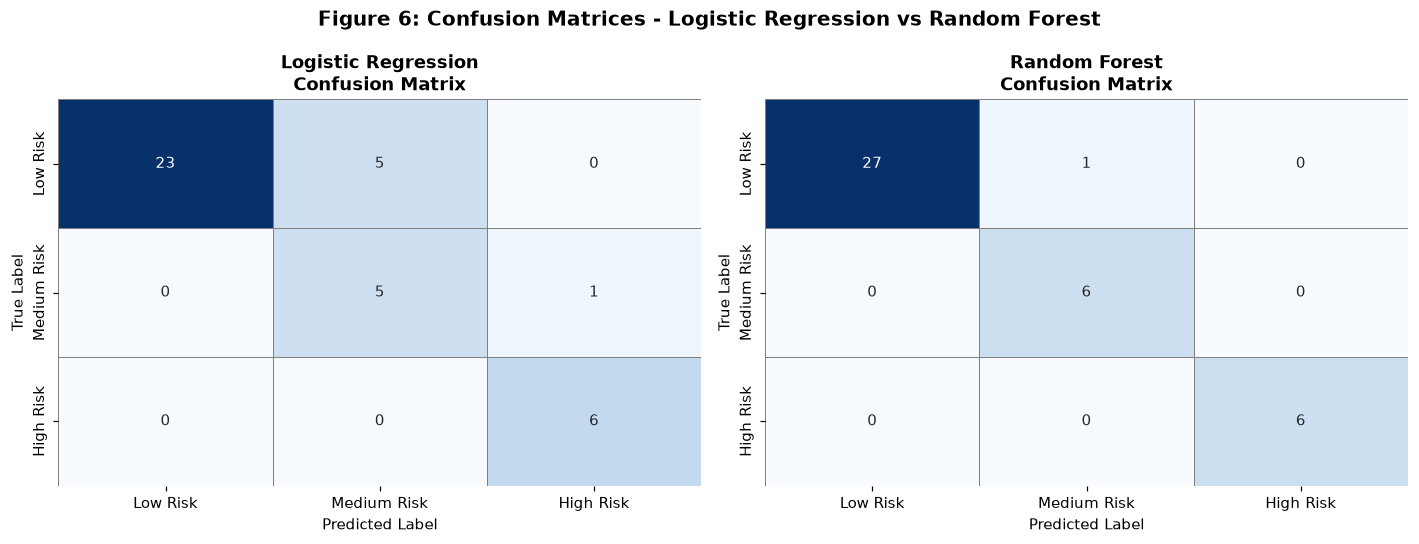

In [21]:
# --- Figure 6: Confusion Matrices ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_pred, title in zip(axes,
                              [y_pred_lr, y_pred_rf],
                              ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=label_names, yticklabels=label_names,
                linewidths=0.5, linecolor='grey', cbar=False)
    ax.set_title(f'{title}\nConfusion Matrix', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.suptitle('Figure 6: Confusion Matrices - Logistic Regression vs Random Forest',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

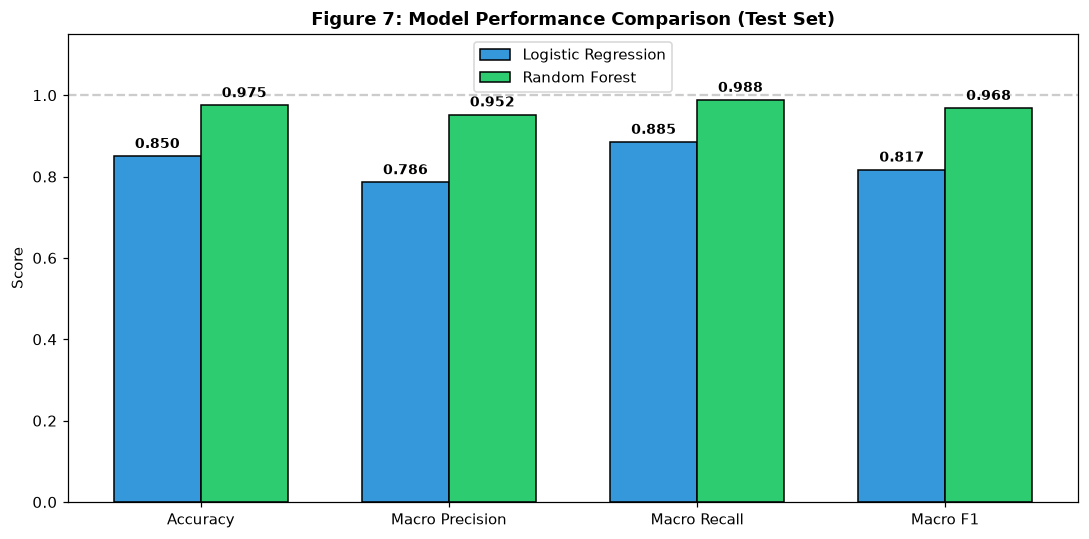

In [22]:
# --- Figure 7: Metrics Comparison Bar Chart ---
x = np.arange(len(summary.columns))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, summary.loc['Logistic Regression'], width,
               label='Logistic Regression', color='#3498db', edgecolor='black')
bars2 = ax.bar(x + width/2, summary.loc['Random Forest'],        width,
               label='Random Forest',        color='#2ecc71', edgecolor='black')

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012,
            f'{bar.get_height():.3f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(summary.columns)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title('Figure 7: Model Performance Comparison (Test Set)', fontsize=12, fontweight='bold')
ax.legend()
ax.axhline(1.0, color='grey', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

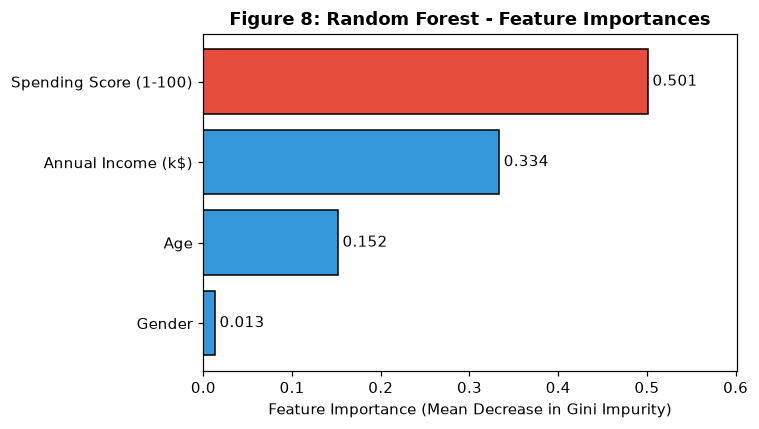

In [23]:
# --- Figure 8: Random Forest Feature Importances ---
fi = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
colors = ['#e74c3c' if i == fi.idxmax() else '#3498db' for i in fi.index]

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(fi.index, fi.values, color=colors, edgecolor='black')
for i, (idx, val) in enumerate(fi.items()):
    ax.text(val + 0.005, i, f'{val:.3f}', va='center', fontsize=10)
ax.set_xlabel('Feature Importance (Mean Decrease in Gini Impurity)')
ax.set_title('Figure 8: Random Forest - Feature Importances', fontsize=12, fontweight='bold')
ax.set_xlim(0, fi.max() + 0.1)
plt.tight_layout()
plt.show()

#### Model evaluation and limits

The executed cells above report holdout accuracy, macro-averaged metrics and training-set cross-validation. The public version fits logistic-regression scaling inside each cross-validation fold, so validation rows do not influence that fold's preprocessing.

This is a 200-row teaching dataset with a 40-row holdout. In this verification run, holdout accuracy was 0.85 for logistic regression and 0.975 for random forest. Training-set cross-validation macro F1 was approximately 0.842 and 0.892 respectively. These scores do not establish real-world churn-prediction performance. The origin and construction of the supplied Churn Risk labels must be understood before interpreting the task as prediction of observed customer departures. Cross-validation cannot resolve that uncertainty.

Macro-averaged metrics give each class equal weight. Read the confusion matrices alongside them, and compare against a simple baseline before considering practical use. The relative business cost of each error type would need stakeholder evidence.

Neither model is presented as validated for operational deployment.


### Part D - Business Intelligence Interpretation

#### Business interpretation

Feature importance describes which variables this fitted random forest uses to distinguish the supplied risk labels. It does not demonstrate why a customer leaves, identify dissatisfaction, or establish that a retention intervention will work.

Income and spending patterns can motivate questions for further research, but the dataset does not establish customer intentions, future churn or the effectiveness of outreach. Before practical use, collect observed outcomes, document label definitions, validate on later or independent data, compare a baseline and assess the consequences of errors.

The lab demonstrates a classification workflow and communication of its limitations. It is not a deployment recommendation.


### Part E - AI‑Age Reflection


##### 1. How did AI assist your analytical process?

AI tools were used minimally in this lab - mainly to accelerate and enhance the analytical workflow. In Part A, AI assisted in structuring the exploratory analysis - suggesting which visualisations are most informative for a multiclass classification problem with imbalanced classes, and identifying the right descriptive statistics to compute. In Parts B and C, AI helped select appropriate preprocessing steps (such as why stratified splitting matters with imbalanced data, and why scaling is needed for Logistic Regression but not Random Forest), and generated well-structured, commented code for both models and all evaluation metrics. This significantly reduced the time spent on boilerplate and syntax, allowing more focus on interpretation and reasoning. In simple terms, AI was used as a learning material and not as a code generation helper.

##### 2. Did you critically evaluate AI-generated outputs?

##### Critical review of AI-generated outputs

The original exercise used AI assistance for parts of the implementation and analysis. Outputs require independent review: a high score on a small teaching dataset does not establish deployment readiness. During preparation of this public version, cross-validation preprocessing was corrected and unsupported operational claims were replaced with explicit limitations. These are publication revisions rather than claims about the original submission.


##### 3. What are the risks of relying blindly on AI in business analytics?

Blind reliance on AI in business analytics carries several serious risks. First, AI models - including the ones suggesting code and analysis in this lab  -  can produce plausible-sounding but incorrect outputs. A model may hallucinate metric values, misinterpret variable relationships, or generate code that silently runs without error yet produces wrong results. Second, AI tends to optimise for surface-level correctness rather than business relevance: it may produce technically valid statistics while missing the managerial implication that matters most to decision-makers. Third, over-reliance on AI removes the analyst's understanding of the process - if an AI-generated model is deployed without human comprehension of its assumptions and limitations, the organisation loses the ability to detect when the model fails or becomes outdated. Finally, there is a risk of automation bias, where human reviewers defer to AI outputs simply because they appear precise and confident, even when they should be challenged. In business analytics, the analyst remains accountable for the conclusions drawn - AI is a tool to assist that process, not replace the critical thinking behind it.